<a href="https://colab.research.google.com/github/Mariana12091/Mineria-de-datos-1/blob/main/IEI097_Actividad_1_9_Mariana_Vasquez.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IEI-097 Minería de Datos — Actividad 1.9
## Mi primer proyecto CRISP-DM

**Estudiante:** Mariana Vásquez  
**Carrera:** Ingeniería en Informática  
**Asignatura:** Minería de Datos  
**Dataset:** Bank Marketing — UCI Machine Learning Repository  
**Fuente:** https://archive.ics.uci.edu/dataset/222/bank  
**Licencia:** Creative Commons Attribution 4.0 International (CC BY 4.0)

> **Objetivo general del proyecto:** explorar un conjunto de datos real de campañas de marketing bancario y representar el conocimiento encontrado mediante reglas de asociación y un árbol de decisión, siguiendo las fases de CRISP-DM.

---


# A. El problema

### Fase CRISP-DM: Comprensión del negocio

El conjunto de datos corresponde a campañas de marketing directo realizadas por una institución bancaria portuguesa mediante llamadas telefónicas. Cada registro contiene información del cliente, características del contacto realizado y antecedentes de campañas anteriores. La variable objetivo `y` indica si el cliente suscribió (`yes`) o no (`no`) un depósito a plazo.

El problema que se abordará es identificar patrones en las características de los clientes y de las campañas que puedan ayudar a comprender el comportamiento observado frente a la oferta de un depósito a plazo.

### Objetivo

El objetivo es descubrir relaciones frecuentes entre características de los clientes y de las campañas mediante reglas de asociación y representar condiciones de clasificación mediante un árbol de decisión. El conocimiento obtenido podría apoyar el análisis y la segmentación de futuras campañas de marketing.

### ¿Por qué utilizar minería de datos?

Este problema no se aborda solamente mediante un promedio o una consulta porque interesa descubrir combinaciones de características que aparecen conjuntamente y condiciones que permiten separar las observaciones en distintas categorías. Las reglas de asociación permiten representar relaciones de coocurrencia, mientras que el árbol de decisión permite transformar combinaciones de atributos en reglas de clasificación fáciles de interpretar.



# B. Los datos

### Fase CRISP-DM: Comprensión de los datos

El dataset utilizado es **Bank Marketing**, disponible en el UCI Machine Learning Repository. UCI informa que contiene 45.211 observaciones y que la versión `bank-full.csv` posee 17 variables en total, incluyendo la variable objetivo `y`. La licencia indicada por UCI es **CC BY 4.0**.

La fuente oficial es:

https://archive.ics.uci.edu/dataset/222/bank

La referencia bibliográfica indicada por UCI es:

Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing*. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306



In [17]:
# Instalación de las bibliotecas necesarias y carga del dataset desde UCI
!pip -q install ucimlrepo mlxtend

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Descargar el dataset oficial de UCI
bank_marketing = fetch_ucirepo(id=222)

X = bank_marketing.data.features.copy()
y = bank_marketing.data.targets.copy()

# Unimos atributos y variable objetivo
df = pd.concat([X, y], axis=1)

print("Dimensiones del dataset:", df.shape)
print("\nColumnas:")
print(df.columns.tolist())

print("\nPrimeras 5 filas:")
display(df.head())


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Dimensiones del dataset: (45211, 17)

Columnas:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Primeras 5 filas:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Diccionario de datos

A continuación se justifican más de los 10 atributos solicitados. Se priorizan variables que permiten describir al cliente, sus condiciones financieras y las características de la campaña.

| Atributo | Tipo | Importancia para el objetivo |
|---|---|---|
| `age` | Entero | Permite analizar diferencias de comportamiento según edad. |
| `job` | Categórico | Permite relacionar el tipo de ocupación con el resultado de la campaña. |
| `marital` | Categórico | Permite observar posibles patrones según estado civil. |
| `education` | Categórico | Permite estudiar la relación entre nivel educacional y respuesta. |
| `default` | Binario | Indica si existe crédito en incumplimiento y aporta información financiera del cliente. |
| `balance` | Entero | Representa el saldo anual promedio y permite analizar diferencias económicas. |
| `housing` | Binario | Indica si el cliente posee crédito hipotecario. |
| `loan` | Binario | Indica si el cliente posee un préstamo personal. |
| `contact` | Categórico | Permite analizar el tipo de comunicación utilizado en el contacto. |
| `day` | Entero | Representa el día del mes del último contacto y permite estudiar posibles patrones temporales. |
| `month` | Categórico | Permite analizar diferencias según el mes de contacto. |
| `duration` | Entero | Representa la duración del último contacto y describe la interacción realizada. |
| `campaign` | Entero | Indica cuántos contactos se realizaron durante la campaña actual. |
| `pdays` | Entero | Indica los días transcurridos desde un contacto anterior y permite identificar antecedentes de campañas. |
| `previous` | Entero | Indica cuántos contactos anteriores tuvo el cliente antes de la campaña actual. |
| `poutcome` | Categórico | Resume el resultado de la campaña de marketing anterior. |
| `y` | Categórico binario | Es la variable objetivo: indica si el cliente suscribió o no un depósito a plazo. |



In [18]:
# Comprobaciones iniciales solicitadas por la pauta
print("Número de filas:", df.shape[0])
print("Número de columnas:", df.shape[1])

print("\nInformación de las variables:")
df.info()

print("\nCantidad de valores nulos por columna:")
display(df.isnull().sum().to_frame("nulos"))

print("\nCantidad de filas duplicadas:")
print(df.duplicated().sum())


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Número de filas: 45211
Número de columnas: 17

Información de las variables:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,nulos
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
contact,13020
day_of_week,0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Cantidad de filas duplicadas:
0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Interpretación de la Parte B

La carga del dataset permite comprobar su tamaño y estructura antes de realizar el análisis. La revisión de los primeros registros permite reconocer cómo están representadas las variables y confirmar que existe una variable objetivo categórica (`y`) con dos clases.

La fuente UCI es apropiada para el proyecto porque proporciona información sobre el origen del dataset, sus variables, su objetivo y su licencia. La versión `bank-full.csv` se encuentra dentro del rango de tamaño solicitado por la actividad y dispone de suficientes atributos para construir el diccionario de datos.



# C. Exploración y preparación — EDA

### Fases CRISP-DM: Comprensión de los datos y Preparación de los datos

En esta etapa se revisará la calidad de los datos, su distribución y las transformaciones necesarias para las representaciones de conocimiento.



In [19]:
# Estadística descriptiva
print("Estadística descriptiva de variables numéricas:")
display(df.describe())

print("\nEstadística descriptiva incluyendo variables categóricas:")
display(df.describe(include="all").T)


Estadística descriptiva de variables numéricas:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000



Estadística descriptiva incluyendo variables categóricas:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,44923,11,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,43354,3,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,32191,2,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Interpretación

La estadística descriptiva permite conocer los rangos y valores frecuentes de las variables numéricas y categóricas. Esto ayuda a detectar valores que requieren atención y a comprender la estructura general del dataset antes de aplicar los métodos de minería de datos.



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Frecuencia de la variable objetivo:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,cantidad
y,
no,39922
yes,5289


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Porcentaje de la variable objetivo:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,porcentaje
y,
no,88.3
yes,11.7


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

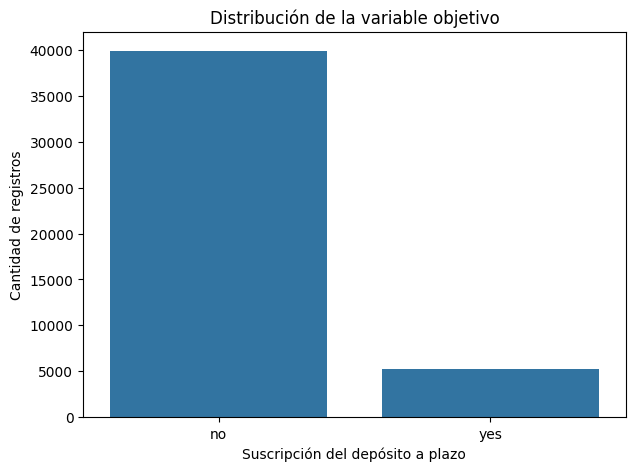

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [20]:
# Distribución de la variable objetivo
objetivo = df["y"].value_counts()
objetivo_pct = df["y"].value_counts(normalize=True).mul(100).round(2)

print("Frecuencia de la variable objetivo:")
display(objetivo.to_frame("cantidad"))

print("Porcentaje de la variable objetivo:")
display(objetivo_pct.to_frame("porcentaje"))

plt.figure(figsize=(7,5))
sns.countplot(data=df, x="y")
plt.title("Distribución de la variable objetivo")
plt.xlabel("Suscripción del depósito a plazo")
plt.ylabel("Cantidad de registros")
plt.show()


### Interpretación del gráfico 1

El gráfico muestra cómo se distribuyen las dos clases de la variable objetivo. Esta revisión es importante porque permite identificar si existe un desbalance entre clientes que suscribieron y que no suscribieron el depósito a plazo. El desbalance debe considerarse al interpretar posteriormente el árbol, ya que una clase con mayor frecuencia puede influir en las decisiones de clasificación.



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

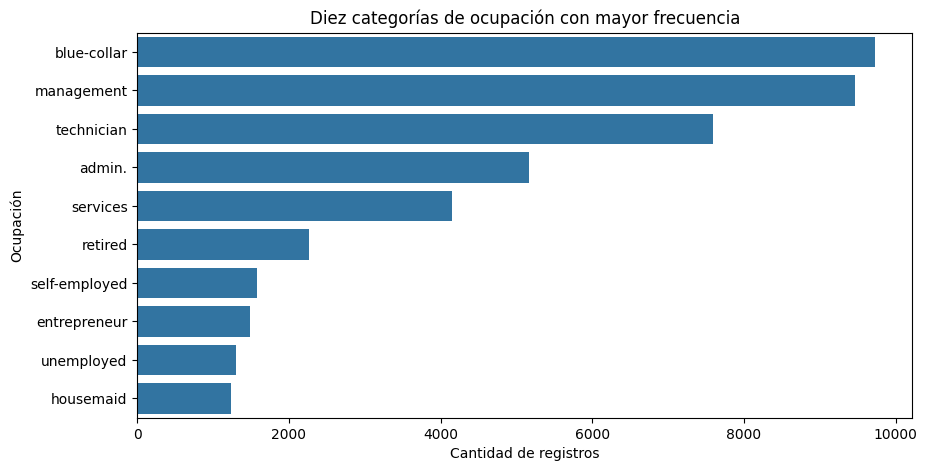

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [21]:
# Visualización 2: distribución de los principales tipos de trabajo
top_jobs = df["job"].value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_jobs.values, y=top_jobs.index)
plt.title("Diez categorías de ocupación con mayor frecuencia")
plt.xlabel("Cantidad de registros")
plt.ylabel("Ocupación")
plt.show()


### Interpretación del gráfico 2

La distribución de ocupaciones permite observar que los registros no se encuentran repartidos de manera uniforme entre todas las categorías laborales. Esta variable resulta útil porque puede aportar información para segmentar los registros y posteriormente analizar si determinados tipos de ocupación aparecen asociados a otras características.



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

y,no,yes
age_group,,
18-30,83.71,16.29
31-45,90.12,9.88
46-60,90.22,9.78
61+,57.74,42.26


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

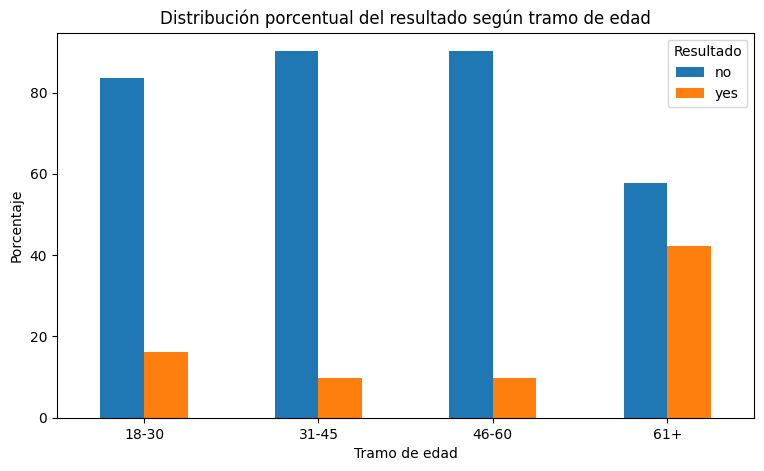

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [22]:
# Visualización 3: edad agrupada y resultado de la campaña
df_eda = df.copy()

df_eda["age_group"] = pd.cut(
    df_eda["age"],
    bins=[0, 30, 45, 60, np.inf],
    labels=["18-30", "31-45", "46-60", "61+"],
    right=True
)

tabla_edad = pd.crosstab(df_eda["age_group"], df_eda["y"], normalize="index").mul(100).round(2)

display(tabla_edad)

tabla_edad.plot(kind="bar", figsize=(9,5))
plt.title("Distribución porcentual del resultado según tramo de edad")
plt.xlabel("Tramo de edad")
plt.ylabel("Porcentaje")
plt.xticks(rotation=0)
plt.legend(title="Resultado")
plt.show()


### Interpretación del gráfico 3

La agrupación de la edad permite comparar el resultado de la campaña entre tramos que son más fáciles de interpretar que valores individuales. Las diferencias observadas entre grupos sirven como antecedente para el análisis posterior, pero no deben interpretarse como una relación causal. El propósito de esta etapa es detectar patrones que puedan ser explorados mediante minería de datos.



In [23]:
# Preparación y control de calidad
df_clean = df.copy()

duplicados_antes = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().copy()
duplicados_despues = df_clean.duplicated().sum()

print("Duplicados antes de limpiar:", duplicados_antes)
print("Duplicados después de limpiar:", duplicados_despues)

print("\nNulos después de la limpieza:")
display(df_clean.isnull().sum().to_frame("nulos"))

print("\nDimensiones después de la limpieza:", df_clean.shape)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Duplicados antes de limpiar: 0
Duplicados después de limpiar: 0

Nulos después de la limpieza:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,nulos
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
contact,13020
day_of_week,0



Dimensiones después de la limpieza: (45211, 17)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Decisiones de preparación

- Los valores nulos se revisaron antes de modelar. La documentación de UCI indica que el dataset no presenta valores faltantes; por ello no es necesario imputar valores.
- Se revisaron las filas duplicadas. Si existen, se eliminan porque representarían observaciones repetidas y podrían alterar artificialmente las frecuencias.
- Para las reglas de asociación se crearán categorías a partir de variables numéricas, ya que el algoritmo trabaja con ítems presentes o ausentes.
- Para el árbol se eliminará `duration` como predictor. La duración corresponde al último contacto y se conoce durante/después de la interacción; utilizarla para apoyar una decisión previa al contacto podría introducir información que no estaría disponible en ese momento. Esta decisión ayuda a evitar una interpretación de fuga de información.
- No se elimina la variable objetivo `y`, porque es necesaria para construir el árbol de decisión.



# D. Reglas de asociación

### Fase CRISP-DM: Modelado

Las reglas de asociación buscan identificar combinaciones de características que aparecen conjuntamente en los registros. Para aplicar este método, las variables se transformarán en ítems binarios.

Se utilizarán 7 variables: `job`, `marital`, `education`, `housing`, `loan`, `contact` y un tramo de edad. Estas variables fueron seleccionadas porque son categóricas o pueden convertirse en categorías interpretables y permiten construir reglas comprensibles en lenguaje de negocio.



In [24]:
# Preparación de datos para reglas de asociación
assoc = df_clean[[
    "job", "marital", "education", "housing",
    "loan", "contact", "age"
]].copy()

# Discretización de la edad
assoc["age_group"] = pd.cut(
    assoc["age"],
    bins=[0, 30, 45, 60, np.inf],
    labels=["edad_18_30", "edad_31_45", "edad_46_60", "edad_61_mas"],
    right=True
)

assoc = assoc.drop(columns=["age"])

# Convertir cada categoría en un ítem binario
assoc_onehot = pd.get_dummies(assoc.astype(str), prefix_sep="=")

print("Columnas seleccionadas:", assoc.columns.tolist())
print("Cantidad de columnas binarias generadas:", assoc_onehot.shape[1])

display(assoc_onehot.head())


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Columnas seleccionadas: ['job', 'marital', 'education', 'housing', 'loan', 'contact', 'age_group']
Cantidad de columnas binarias generadas: 30


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,job=admin.,job=blue-collar,job=entrepreneur,job=housemaid,job=management,job=nan,job=retired,job=self-employed,job=services,job=student,...,housing=yes,loan=no,loan=yes,contact=cellular,contact=nan,contact=telephone,age_group=edad_18_30,age_group=edad_31_45,age_group=edad_46_60,age_group=edad_61_mas
0,False,False,False,False,True,False,False,False,False,False,...,True,True,False,False,True,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,...,True,True,False,False,True,False,False,True,False,False
2,False,False,True,False,False,False,False,False,False,False,...,True,False,True,False,True,False,False,True,False,False
3,False,True,False,False,False,False,False,False,False,False,...,True,True,False,False,True,False,False,False,True,False
4,False,False,False,False,False,True,False,False,False,False,...,False,True,False,False,True,False,False,True,False,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Interpretación

La transformación convierte cada categoría en un ítem binario. Por ejemplo, un registro puede contener simultáneamente los ítems `housing=yes`, `loan=no` y `edad_31_45`. Esto permite que el algoritmo busque combinaciones frecuentes de características.



In [25]:
from mlxtend.frequent_patterns import apriori, association_rules

# Probamos distintos niveles de soporte para observar cómo cambia el resultado
resultados_parametros = []

for min_support in [0.10, 0.07, 0.05, 0.03, 0.02]:
    itemsets_temp = apriori(
        assoc_onehot,
        min_support=min_support,
        use_colnames=True
    )

    if len(itemsets_temp) >= 2:
        rules_temp = association_rules(
            itemsets_temp,
            metric="confidence",
            min_threshold=0.30
        )
    else:
        rules_temp = pd.DataFrame()

    resultados_parametros.append({
        "min_support": min_support,
        "itemsets_frecuentes": len(itemsets_temp),
        "reglas_generadas": len(rules_temp)
    })

parametros_df = pd.DataFrame(resultados_parametros)
display(parametros_df)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,min_support,itemsets_frecuentes,reglas_generadas
0,0.10,181,639
1,0.07,313,1274
2,0.05,492,2130
3,0.03,877,4329
4,0.02,1318,6860


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Interpretación de los parámetros

La tabla permite observar el efecto de modificar `min_support`. Al disminuir el soporte mínimo se permite considerar patrones que aparecen en una proporción menor de los registros, por lo que normalmente aumenta la cantidad de conjuntos frecuentes y reglas disponibles.

Se seleccionará un soporte que entregue suficientes reglas para interpretar, evitando utilizar un umbral tan bajo que produzca una cantidad excesiva de combinaciones poco representativas.



In [26]:
# Selección automática de parámetros con suficientes reglas interpretables
configuraciones = [
    (0.10, 0.50),
    (0.07, 0.50),
    (0.05, 0.50),
    (0.03, 0.50),
    (0.02, 0.40),
    (0.01, 0.40)
]

itemsets = None
reglas = None
soporte_elegido = None
confianza_elegida = None

for min_support, min_confidence in configuraciones:
    candidatos = apriori(
        assoc_onehot,
        min_support=min_support,
        use_colnames=True
    )

    if len(candidatos) > 0:
        reglas_candidatas = association_rules(
            candidatos,
            metric="confidence",
            min_threshold=min_confidence
        )

        reglas_candidatas = reglas_candidatas[
            reglas_candidatas["lift"] > 1
        ].copy()

        if len(reglas_candidatas) >= 3:
            itemsets = candidatos
            reglas = reglas_candidatas
            soporte_elegido = min_support
            confianza_elegida = min_confidence
            break

if reglas is None:
    raise ValueError("No se encontraron suficientes reglas. Disminuye los umbrales de la lista de configuraciones.")

print("Support mínimo seleccionado:", soporte_elegido)
print("Confidence mínimo seleccionado:", confianza_elegida)
print("Cantidad de conjuntos frecuentes:", len(itemsets))
print("Cantidad de reglas con lift > 1:", len(reglas))


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Support mínimo seleccionado: 0.1
Confidence mínimo seleccionado: 0.5
Cantidad de conjuntos frecuentes: 181
Cantidad de reglas con lift > 1: 233


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Justificación de los parámetros elegidos

Los parámetros no se seleccionaron arbitrariamente. Primero se probaron diferentes valores de `min_support` y se observó cómo cambiaba la cantidad de patrones. Luego se seleccionó una configuración que permite obtener al menos tres reglas con `lift > 1`, manteniendo un soporte y una confianza suficientemente exigentes para que las reglas sean interpretables.

Un `lift` superior a 1 indica que los elementos del antecedente y consecuente aparecen conjuntamente con mayor frecuencia de la que se esperaría bajo independencia. Por eso se utilizará como criterio complementario para seleccionar reglas que tengan una relación positiva observable.



In [27]:
# Seleccionar las tres reglas principales por lift
reglas_top = reglas.sort_values(
    by=["lift", "confidence", "support"],
    ascending=False
).head(3).copy()

def formatear_items(items):
    return ", ".join(sorted(str(x) for x in items))

reglas_top["antecedente"] = reglas_top["antecedents"].apply(formatear_items)
reglas_top["consecuente"] = reglas_top["consequents"].apply(formatear_items)

tabla_reglas = reglas_top[
    ["antecedente", "consecuente", "support", "confidence", "lift"]
].copy()

tabla_reglas["regla"] = (
    tabla_reglas["antecedente"] + " → " +
    tabla_reglas["consecuente"]
)

tabla_reglas = tabla_reglas[
    ["regla", "support", "confidence", "lift"]
].reset_index(drop=True)

tabla_reglas["support"] = tabla_reglas["support"].round(4)
tabla_reglas["confidence"] = tabla_reglas["confidence"].round(4)
tabla_reglas["lift"] = tabla_reglas["lift"].round(4)

display(tabla_reglas)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,regla,support,confidence,lift
0,"age_group=edad_31_45, education=tertiary → job...",0.1029,0.6098,2.9151
1,"contact=cellular, job=management, loan=no → ed...",0.1152,0.8566,2.9115
2,"contact=cellular, job=management → education=t...",0.1152,0.7416,2.9113


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Interpretación de las tres reglas

La tabla anterior contiene las tres reglas seleccionadas a partir de los resultados obtenidos con el dataset.

**Support:** indica la proporción de todos los registros en los que aparecen conjuntamente el antecedente y el consecuente.

**Confidence:** indica, entre los registros que contienen el antecedente, qué proporción también contiene el consecuente.

**Lift:** compara la frecuencia observada de la combinación con la frecuencia esperada si antecedente y consecuente fueran independientes. Un valor superior a 1 indica una asociación positiva.

En términos de negocio, cada regla puede leerse como: **cuando se presentan las condiciones del antecedente, es frecuente observar también la condición del consecuente**. Estas relaciones podrían utilizarse como apoyo para segmentar clientes o comprender combinaciones frecuentes dentro de las campañas. No deben interpretarse como relaciones causales.

**Importante:** los valores concretos de las tres reglas mostradas arriba son calculados directamente a partir del dataset en este notebook y no deben reemplazarse por números escritos manualmente.



# E. Árbol de decisión

### Fase CRISP-DM: Modelado

La variable objetivo seleccionada es `y`, que posee dos clases: `no` y `yes`. El objetivo del árbol es representar de forma comprensible qué combinaciones de atributos separan los registros según el resultado de la campaña.

Se eliminarán columnas que no aportan información útil como identificadores y se excluirá `duration` para evitar utilizar información que se conoce durante/después del contacto. La profundidad máxima será 4, tal como solicita la actividad.



In [28]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

# Copia para modelado
tree_df = df_clean.copy()

# Variable objetivo
y_tree = tree_df["y"].map({"no": 0, "yes": 1})

# Predictores: excluimos la variable objetivo y duration
# duration se excluye porque corresponde a información de la interacción
# que se conoce durante/después del contacto.
features_tree = [
    "age", "job", "marital", "education", "default",
    "balance", "housing", "loan", "contact", "day",
    "month", "campaign", "pdays", "previous", "poutcome"
]

X_tree_raw = tree_df[features_tree].copy()

# Convertimos variables categóricas a variables binarias
X_tree = pd.get_dummies(
    X_tree_raw,
    columns=[
        "job", "marital", "education", "default",
        "housing", "loan", "contact", "month", "poutcome"
    ],
    drop_first=False
)

print("Cantidad de variables utilizadas por el árbol:", X_tree.shape[1])
print("Clases de la variable objetivo:", sorted(tree_df["y"].unique()))


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

KeyError: "['day'] not in index"

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# Entrenamiento del árbol con profundidad máxima 4
tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

tree_model.fit(X_tree, y_tree)

print("Profundidad real del árbol:", tree_model.get_depth())
print("Cantidad de hojas:", tree_model.get_n_leaves())

# Identificar atributo de la raíz
root_index = tree_model.tree_.feature[0]
root_feature = X_tree.columns[root_index]

print("Atributo utilizado en la raíz:", root_feature)


### Interpretación de la raíz

El atributo indicado por la salida anterior es la primera división del árbol. El algoritmo selecciona esa variable porque, entre las alternativas disponibles, proporciona la división que más reduce la impureza según el criterio utilizado por el árbol (`gini`).

La raíz no debe interpretarse como una causa del resultado. Representa la primera condición que el modelo utiliza para separar las observaciones.



In [ ]:
# Gráfico del árbol
plt.figure(figsize=(24, 13))

plot_tree(
    tree_model,
    feature_names=X_tree.columns,
    class_names=["no", "yes"],
    filled=True,
    rounded=True,
    proportion=True,
    precision=2,
    fontsize=8
)

plt.title("Árbol de decisión — profundidad máxima 4")
plt.show()


### Interpretación del árbol

El gráfico representa las decisiones del modelo desde la raíz hasta las hojas. Cada nodo contiene una condición que divide los registros y cada hoja muestra la clase predominante.

La profundidad máxima de 4 permite mantener una representación que puede leerse y traducirse a reglas de negocio. Un árbol mucho más profundo podría generar muchas ramas, hacer más difícil la interpretación y capturar detalles demasiado específicos de los datos. Por este motivo se mantiene la restricción solicitada por la actividad.



In [ ]:
# Versión textual del árbol
reglas_texto = export_text(
    tree_model,
    feature_names=list(X_tree.columns),
    max_depth=4,
    decimals=2,
    show_weights=True
)

print(reglas_texto)


### Interpretación de las reglas de texto

La versión textual permite leer el árbol como una secuencia de condiciones. Cada camino desde la raíz hasta una hoja puede convertirse en una regla de negocio.

A continuación se generan automáticamente dos caminos completos para evitar copiar manualmente condiciones incorrectas del gráfico.



In [ ]:
# Extraer dos caminos raíz-hoja del árbol y convertirlos en reglas legibles
from collections import defaultdict

tree_ = tree_model.tree_
feature_names = np.array(X_tree.columns)

def obtener_caminos(node=0, condiciones=None):
    if condiciones is None:
        condiciones = []

    izquierda = tree_.children_left[node]
    derecha = tree_.children_right[node]

    # Es una hoja
    if izquierda == derecha:
        muestras = tree_.n_node_samples[node]
        clase = tree_model.classes_[np.argmax(tree_.value[node][0])]
        return [{
            "condiciones": condiciones,
            "muestras": muestras,
            "clase": "yes" if clase == 1 else "no"
        }]

    caminos = []
    feature = feature_names[tree_.feature[node]]
    threshold = tree_.threshold[node]

    caminos += obtener_caminos(
        izquierda,
        condiciones + [(feature, "<=", threshold)]
    )

    caminos += obtener_caminos(
        derecha,
        condiciones + [(feature, ">", threshold)]
    )

    return caminos

caminos = obtener_caminos()

# Preferimos caminos con más observaciones para que sean más representativos
caminos = sorted(caminos, key=lambda x: x["muestras"], reverse=True)[:2]

def condicion_legible(feature, operador, threshold):
    # Para variables one-hot, > 0.5 significa que la categoría está presente
    if "_" in feature and operador in [">", "<="] and threshold == 0.5:
        base, categoria = feature.split("_", 1)
        if operador == ">":
            return f"{base} = {categoria}"
        else:
            return f"{base} != {categoria}"

    return f"{feature} {operador} {threshold:.2f}"

for i, camino in enumerate(caminos, start=1):
    condiciones_legibles = [
        condicion_legible(f, op, t)
        for f, op, t in camino["condiciones"]
    ]

    print(f"CAMINO {i}")
    print("SI " + " Y ".join(condiciones_legibles))
    print(f"ENTONCES clasificación = {camino['clase']}")
    print(f"Registros que llegan a esta hoja: {camino['muestras']}")
    print("-" * 80)


### Dos caminos traducidos a reglas de negocio

**Camino 1:** La salida de código anterior representa el primer camino seleccionado desde la raíz hasta una hoja. En lenguaje de negocio, significa que cuando se cumplen simultáneamente las condiciones mostradas por el árbol, el registro es clasificado en la categoría indicada.

**Camino 2:** La segunda salida representa otro camino completo desde la raíz hasta una hoja. En lenguaje de negocio, las condiciones pueden utilizarse como una regla descriptiva para identificar registros con características similares a las observadas en esa hoja.

Estas reglas describen patrones aprendidos por el árbol y no deben interpretarse como relaciones causales. La utilidad principal es facilitar la lectura del conocimiento descubierto.



### ¿Qué decisión podría apoyar el árbol?

El árbol podría apoyar una primera segmentación de registros de campañas según las características disponibles. Por ejemplo, podría ayudar a identificar grupos que presentan condiciones asociadas a una determinada clasificación y servir como apoyo para priorizar análisis comerciales posteriores.

El árbol no debería utilizarse como una decisión automática definitiva sin una evaluación adicional en datos nuevos, revisión del contexto comercial y consideración de aspectos éticos y de privacidad.



# F. Síntesis y proceso CRISP-DM

### Fases CRISP-DM: revisión completa del proyecto

### Comparación de las representaciones

| Representación | Tipo de conocimiento | Cuándo resulta útil | Limitación |
|---|---|---|---|
| Reglas de asociación | Relaciones de coocurrencia entre ítems | Para descubrir combinaciones frecuentes sin definir necesariamente una variable objetivo | Muchas reglas pueden ser redundantes y una asociación no implica causalidad. |
| Árbol de decisión | Reglas jerárquicas de clasificación | Para representar condiciones que llevan a una clasificación concreta | Puede volverse difícil de interpretar si aumenta demasiado su profundidad y puede verse afectado por los datos utilizados para construirlo. |

En este proyecto, las reglas de asociación permiten observar combinaciones frecuentes entre características de los clientes y las campañas, mientras que el árbol organiza condiciones en caminos que terminan en una clasificación.

### Limitaciones del análisis

- El dataset representa campañas de una institución bancaria portuguesa y no necesariamente representa a otros bancos o poblaciones.
- Las asociaciones encontradas describen coocurrencias y no demuestran causalidad.
- El árbol fue limitado a profundidad 4 para favorecer la interpretación, por lo que no representa todas las posibles relaciones existentes.
- La exclusión de `duration` evita utilizar información conocida durante/después del contacto para una decisión previa, pero también significa que se renuncia a una variable que podría tener alta capacidad descriptiva.
- Para poner el proyecto en producción sería necesario evaluar el comportamiento del conocimiento obtenido con datos nuevos y revisar periódicamente si los patrones se mantienen.

### Tabla de fases CRISP-DM

| Fase | Qué se realizó o propondría | Parte |
|---|---|---|
| Comprensión del negocio | Se definió el contexto de las campañas bancarias, el problema y el objetivo del análisis. | A |
| Comprensión de los datos | Se identificó la fuente, tamaño, variables, objetivo y características principales del dataset. | B |
| Preparación de los datos | Se revisaron nulos y duplicados, se realizaron discretizaciones para asociación y transformaciones para el árbol. | C |
| Modelado | Se generaron reglas de asociación y un árbol de decisión con profundidad máxima 4. | D y E |
| Evaluación | Se interpretaron las reglas, los caminos del árbol, sus limitaciones y el tipo de conocimiento entregado por cada representación. | F |
| Despliegue | Se propondría utilizar los resultados como apoyo para segmentación y análisis de campañas, validándolos previamente con datos nuevos y expertos del negocio. | F |

### Propuesta de evaluación y puesta en uso

Antes de utilizar el proyecto en una situación real, propondría comprobar si las reglas se mantienen en campañas posteriores y si los caminos del árbol continúan siendo interpretables y útiles. También sería necesario revisar periódicamente los patrones porque el comportamiento de los clientes puede cambiar con el tiempo.

El uso final debería considerarse como apoyo al análisis y no como una decisión automática. Las reglas y el árbol deberían ser revisados por responsables del negocio antes de convertirlos en acciones concretas.



# G. Autoría y uso de herramientas

### Declaración de autoría

Declaro que este trabajo corresponde a mi proyecto individual para la asignatura IEI-097 Minería de Datos y que puedo explicar el propósito, funcionamiento e interpretación de las partes desarrolladas en el notebook.

### Uso de herramientas de IA

Se utilizó una herramienta de inteligencia artificial generativa como apoyo para comprender conceptos de minería de datos, organizar la estructura del notebook, resolver dudas de programación y revisar la presentación de las interpretaciones. La estudiante revisó el código, ejecutó el análisis, verificó los resultados obtenidos y debe ser capaz de explicar cada parte del proyecto.

### Fuente y licencia

**Dataset:** Bank Marketing — UCI Machine Learning Repository  
**Fuente:** https://archive.ics.uci.edu/dataset/222/bank  
**Licencia:** Creative Commons Attribution 4.0 International (CC BY 4.0)  
**Referencia:** Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing*. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306

### Aprendizaje principal

El principal aprendizaje de este proyecto fue comprender que la minería de datos no consiste solamente en ejecutar algoritmos, sino en transformar datos en conocimiento interpretable. Las reglas de asociación permiten descubrir relaciones frecuentes, mientras que el árbol de decisión permite representar condiciones de clasificación de una forma que puede comunicarse con mayor facilidad.

### Repositorio GitHub

**Enlace:** https://github.com/Mariana12091



# Checklist antes de entregar

- [ ] Ejecuté todas las celdas desde el principio hasta el final sin errores.
- [ ] Revisé que el dataset cargado sea Bank Marketing de UCI.
- [ ] A, B, C, D, E, F y G están completas y en orden.
- [ ] Cada parte tiene identificada su fase de CRISP-DM.
- [ ] El diccionario contiene más de 10 atributos y justifica su importancia.
- [ ] Realicé revisión de nulos y duplicados.
- [ ] Incluí al menos 2 visualizaciones y escribí su interpretación.
- [ ] Justifiqué las decisiones de preparación.
- [ ] Probé distintos valores de `min_support`.
- [ ] Presenté al menos 3 reglas con support, confidence y lift.
- [ ] Interpreté las reglas en lenguaje de negocio.
- [ ] El árbol tiene `max_depth=4`.
- [ ] Mostré el gráfico y las reglas de texto del árbol.
- [ ] Identifiqué la raíz y expliqué por qué aparece primero.
- [ ] Presenté 2 caminos del árbol como reglas de negocio.
- [ ] Comparé reglas de asociación y árbol.
- [ ] Incluí la tabla completa de CRISP-DM.
- [ ] Incluí limitaciones y propuesta de uso.
- [ ] Declaré el uso de IA de manera transparente.
- [ ] Agregué el enlace de GitHub.
- [ ] Sincronicé el notebook con GitHub.
- [ ] Compartí el enlace de Colab con permiso de comentarista.
- [ ] Entregué ambos enlaces en Moodle.
